# 02 EDA

Add exploratory data analysis steps here.

## 2.1. Phân tích mối quan hệ giữa các biến

Phân tích mối quan hệ giữa các biến nhằm xác định những yếu tố có liên hệ với mức độ phổ biến và phản hồi của người chơi đối với các trò chơi trên Steam. Các biến được xem xét gồm giá bán (Price), số lượt đánh giá tích cực (Positive), số lượt đánh giá tiêu cực (Negative), lượng người chơi đồng thời cao nhất (Peak CCU), số lượt đề xuất (Recommendations), điểm Metacritic và thời gian chơi trung bình.

## 2.2. So sánh giữa các nhóm đối tượng

Các trò chơi được phân nhóm theo giá bán, thể loại và nền tảng hỗ trợ. Việc so sánh giữa game miễn phí và game trả phí giúp khảo sát sự khác biệt về mức độ phổ biến và tỷ lệ đánh giá tích cực. Phân tích theo thể loại cho phép xác định những thể loại phổ biến và sự khác biệt về giá bán giữa chúng. Ngoài ra, việc so sánh game theo nền tảng Windows, Mac và Linux giúp đánh giá mức độ đa dạng trong hỗ trợ hệ điều hành.

## 2.3 Code python

### 2.3.1. Khai báo thư viện

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv(r"../data/processed/games_reduced.csv")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14

print("Kích thước dataset:", df.shape)
print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df.describe(include="all").T)

print("\nSố lượng giá trị thiếu:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing"))

Kích thước dataset: (125855, 26)

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 26 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id                          125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   Positive                    125855 non-null  int64  
 10  Negative                    125855 non-null  int64  
 11  User score                  125855 non-null  int64  
 12  Metacritic score            12

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,125855.0,NaN,NaN,NaN,2032626.605236,1117434.092973,10.0,1083495.0,1949010.0,2938410.0,4437540.0
Name,125854,124644,Shadow of the Tomb Raider: Definitive Edition,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Release date,125855,5141,"Oct 23, 2025",190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated owners,125855,14,0 - 20000,75705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Peak CCU,125855.0,NaN,NaN,NaN,53.1872,3681.082965,0.0,0.0,0.0,0.0,1013936.0
Required age,125855.0,NaN,NaN,NaN,0.165365,1.642666,0.0,0.0,0.0,0.0,21.0
Price,125855.0,NaN,NaN,NaN,4.811174,12.489329,0.0,0.59,2.39,5.545,999.98
Discount,125855.0,NaN,NaN,NaN,17.896826,28.628518,0.0,0.0,0.0,37.0,100.0
DLC count,125855.0,NaN,NaN,NaN,0.535434,14.328417,0.0,0.0,0.0,0.0,3703.0
Positive,125855.0,NaN,NaN,NaN,1018.182091,27727.824406,0.0,0.0,4.0,35.0,7642084.0



Số lượng giá trị thiếu:


,Missing
Tags,42502
Categories,8966
Publishers,8922
Developers,8449
Genres,8423
Name,1
Release date,0
Estimated owners,0
Peak CCU,0
id,0


### 2.3.2. Phân phối giá game 

Tổng số game có giá hợp lệ: 125855
Tổng các cột trong biểu đồ: 125855
Game miễn phí: 26661 (21.2%)
Game trả phí dưới 1 USD: 20261
Game từ 30 USD trở lên: 1146


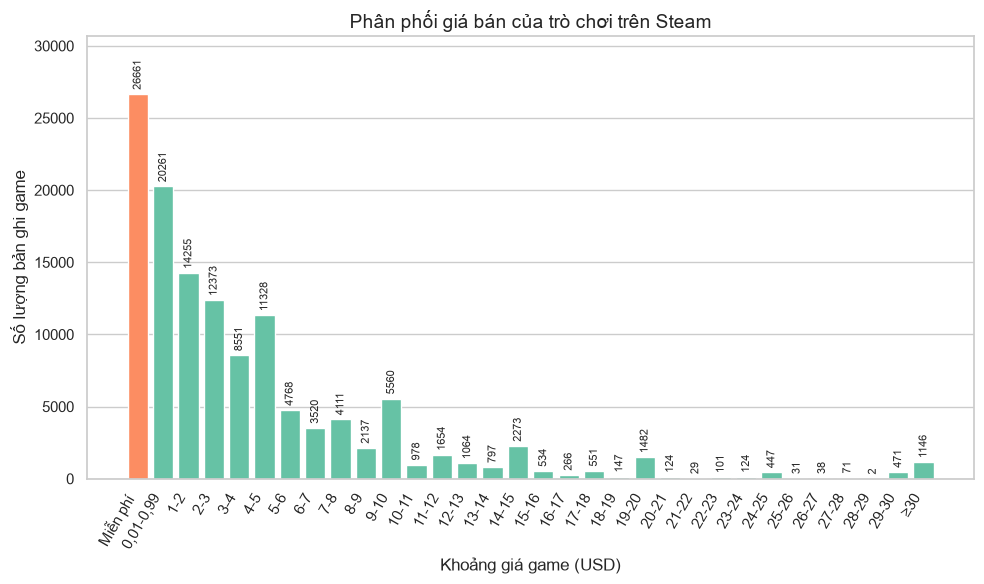

In [18]:
prices = df["Price"].dropna()
free = prices[prices == 0]
paid = prices[prices > 0]

edges = list(range(0, 31)) + [np.inf]
paid_labels = ["0,01-0,99"] + [f"{i}-{i+1}" for i in range(1, 30)] + ["≥30"]
paid_counts = (pd.cut(paid, bins=edges, labels=paid_labels, right=False)
                 .value_counts().reindex(paid_labels))

counts = pd.concat([pd.Series({"Miễn phí": len(free)}), paid_counts])
colors = [sns.color_palette()[1]] + [sns.color_palette()[0]] * len(paid_counts)

print("Tổng số game có giá hợp lệ:", len(prices))
print("Tổng các cột trong biểu đồ:", counts.sum())
print("Game miễn phí:", len(free), f"({len(free)/len(prices):.1%})")
print("Game trả phí dưới 1 USD:", paid_counts["0,01-0,99"])
print("Game từ 30 USD trở lên:", paid_counts["≥30"])

plt.figure()
ax = plt.gca()
ax.bar(range(len(counts)), counts.values, color=colors, edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%d", rotation=90, fontsize=8, padding=3)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=60, ha="right")
ax.grid(axis="x", visible=False)
ax.set(title="Phân phối giá bán của trò chơi trên Steam",
       xlabel="Khoảng giá game (USD)", ylabel="Số lượng bản ghi game")
plt.tight_layout()
plt.show()

Nhận xét:

1. Phân phối lệch phải rất mạnh, đa số game có giá thấp.

-Cột 0–1 USD cao nhất với 46.922 game, chiếm khoảng 37,3% tổng số 125.855 game.

-Khoảng 74% game có giá dưới 5 USD và khoảng 90% dưới 10 USD.

-Số game giảm dần khi giá tăng. Nhóm từ 30 USD trở lên chỉ có 1.146 game, chiếm chưa tới 1%.

-Game miễn phí có 26.661 game, chiếm 21,2% tổng số, và là cột cao nhất của biểu đồ.

2. Phân khúc giá cao rất ít game.

-Từ 10 USD trở lên, mỗi khoảng chỉ còn vài trăm đến vài nghìn game, và từ 20 USD trở đi hầu hết các khoảng dưới 500 game (riêng 19–20 USD có 1.482 game).

Kết luận: thị trường Steam trong dữ liệu này tập trung vào game giá rẻ và game miễn phí, chủ yếu dưới 5 USD. Giá bán có xu hướng tập trung vào một số mức quen thuộc như 4,99, 9,99 và 14,99 USD thay vì trải đều.

### 2.3.3. Ma trận tương quan giữa các biến số

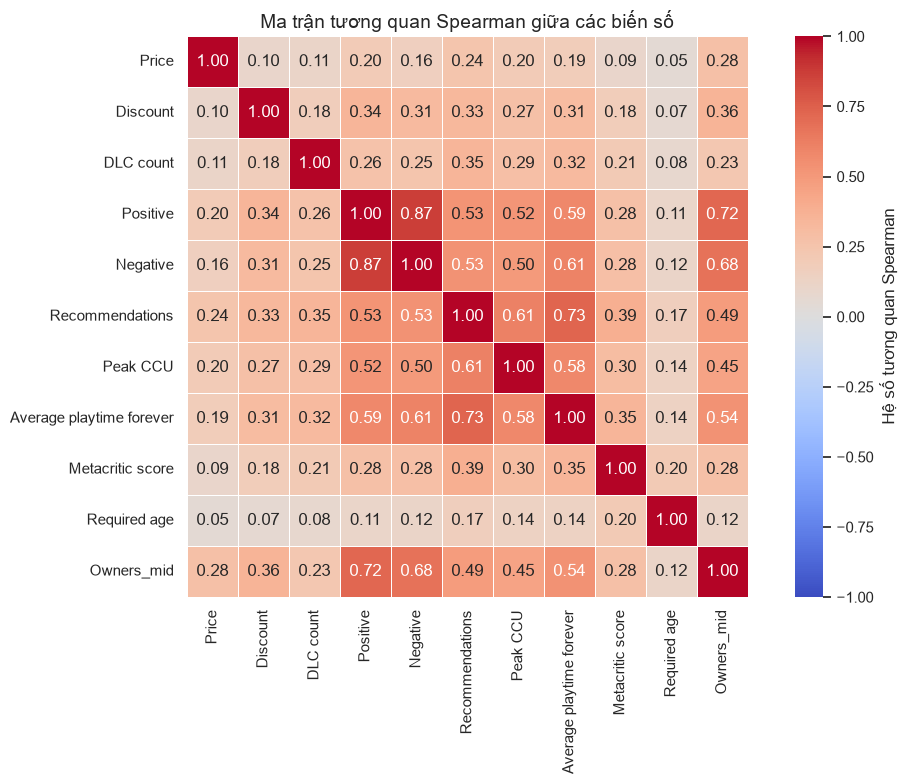

In [ ]:
lo = df["Estimated owners"].str.split(" - ").str[0].astype(float)
hi = df["Estimated owners"].str.split(" - ").str[1].astype(float)
data = df.assign(Owners_mid=(lo + hi) / 2)   # đổi khoảng owners thành số (điểm giữa)

cols = ["Price", "Discount", "DLC count", "Positive", "Negative", "Recommendations",
        "Peak CCU", "Average playtime forever", "Metacritic score", "Required age", "Owners_mid"]

corr = data[cols].corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, square=True, cbar_kws={"label": "Hệ số tương quan Spearman"})
plt.title("Ma trận tương quan giữa các biến số")
plt.tight_layout()
plt.show()

-Nhận xét:

1.Tương quan mạnh (từ 0,5 trở lên):

-Positive ~ Negative: 0,87. Game có nhiều đánh giá tốt thường cũng có nhiều đánh giá xấu. Con số này phản ánh độ nổi tiếng

-Positive ~ Owners_mid: 0,72, và Negative ~ Owners_mid: 0,68. Càng nhiều người sở hữu thì càng nhiều đánh giá.

-Recommendations ~ Average playtime forever: 0,73, và Recommendations ~ Peak CCU: 0,61. Game được đề xuất nhiều thường được chơi lâu hơn và có nhiều người chơi đồng thời hơn.

2.Tương quan yếu (dưới 0,3):

-Price với hầu hết biến khác chỉ khoảng 0,1–0,28, nghĩa là giá không quyết định độ nổi tiếng.

-Required age gần như không liên quan (cao nhất chỉ 0,20 với Metacritic).

### 2.3.4. Mối quan hệ giữa lượt đề xuất và lượng người chơi

                so_game  ccu_trung_vi
nhom                                 
101-200            5881           0.0
201-500            5696           1.0
501-1.000          3066           2.0
1.001-5.000        4034           9.0
5.001-10.000        885          42.0
10.001-50.000      1060         179.5
50.001-100.000      200         739.0
>100.000            192        4004.0


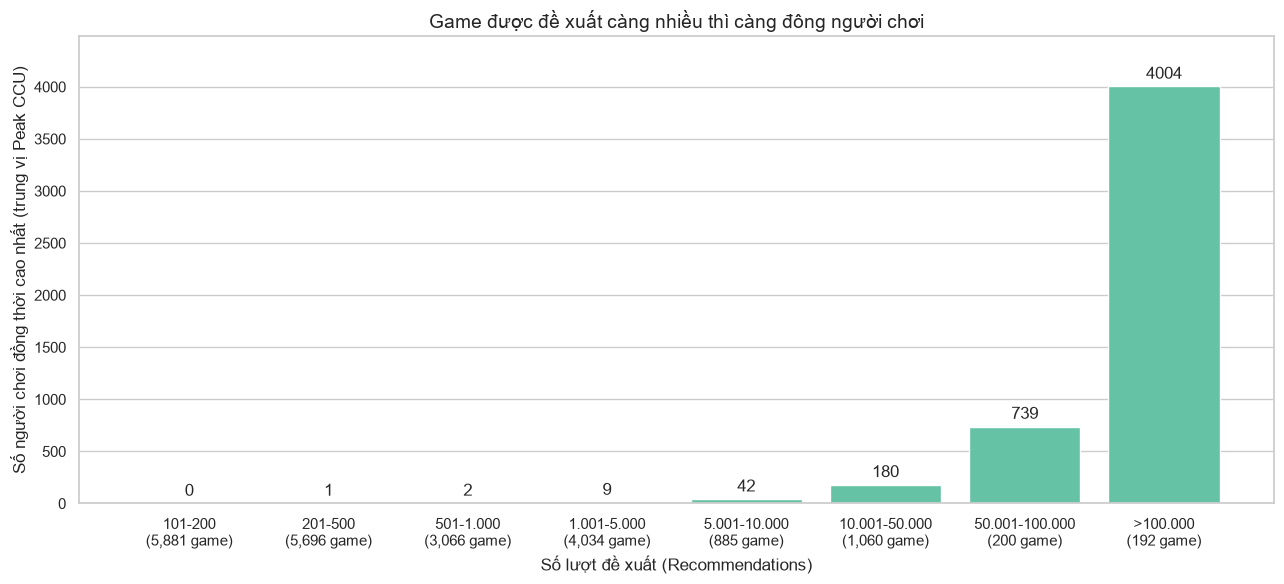

In [22]:
d = df[df["Recommendations"] > 0].copy()          # chỉ xét game có lượt đề xuất

edges  = [0, 200, 500, 1000, 5000, 10000, 50000, 100000, np.inf]
labels = ["101-200", "201-500", "501-1.000", "1.001-5.000",
          "5.001-10.000", "10.001-50.000", "50.001-100.000", ">100.000"]
d["nhom"] = pd.cut(d["Recommendations"], bins=edges, labels=labels, right=True)

tong_hop = d.groupby("nhom", observed=True).agg(
    so_game=("Peak CCU", "size"),
    ccu_trung_vi=("Peak CCU", "median"),
)
print(tong_hop)

plt.figure(figsize=(13, 6))
ax = plt.gca()
ax.bar(range(len(tong_hop)), tong_hop["ccu_trung_vi"], edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_xticks(range(len(tong_hop)))
ax.set_xticklabels([f"{l}\n({n:,} game)" for l, n in zip(tong_hop.index, tong_hop["so_game"])])
ax.grid(axis="x", visible=False)
ax.set_ylim(0, tong_hop["ccu_trung_vi"].max() * 1.12)
ax.set(title="Game được đề xuất càng nhiều thì càng đông người chơi",
       xlabel="Số lượt đề xuất (Recommendations)",
       ylabel="Số người chơi đồng thời cao nhất (trung vị Peak CCU)")
plt.tight_layout()
plt.show()

Nhận xét

-Lượt đề xuất càng nhiều thì người chơi càng đông, và tăng rất nhanh ở nhóm cuối. Trung vị Peak CCU là 0–2 ở nhóm dưới 1.000 lượt, 9 ở nhóm 1.001–5.000, rồi 180 ở nhóm 10.001–50.000, 739 ở nhóm 50.001–100.000 và 4.004 ở nhóm trên 100.000.

-Phần lớn game nằm ở các nhóm thấp. Hai nhóm dưới 500 lượt có tới 11.577 game (khoảng 55%), trong khi nhóm trên 100.000 lượt chỉ có 192 game. Cột cao nhưng chỉ đại diện cho một nhóm nhỏ game rất nổi tiếng.

-Các cột đầu gần như bằng 0 nhưng không phải lỗi. Game có ít lượt đề xuất thường chỉ có 0–2 người chơi đồng thời ở thời điểm ghi nhận, nên cột rất thấp, chỉ thấy số ghi trên đầu cột.

### 2.3.5.  So sánh game miễn phí và game trả phí

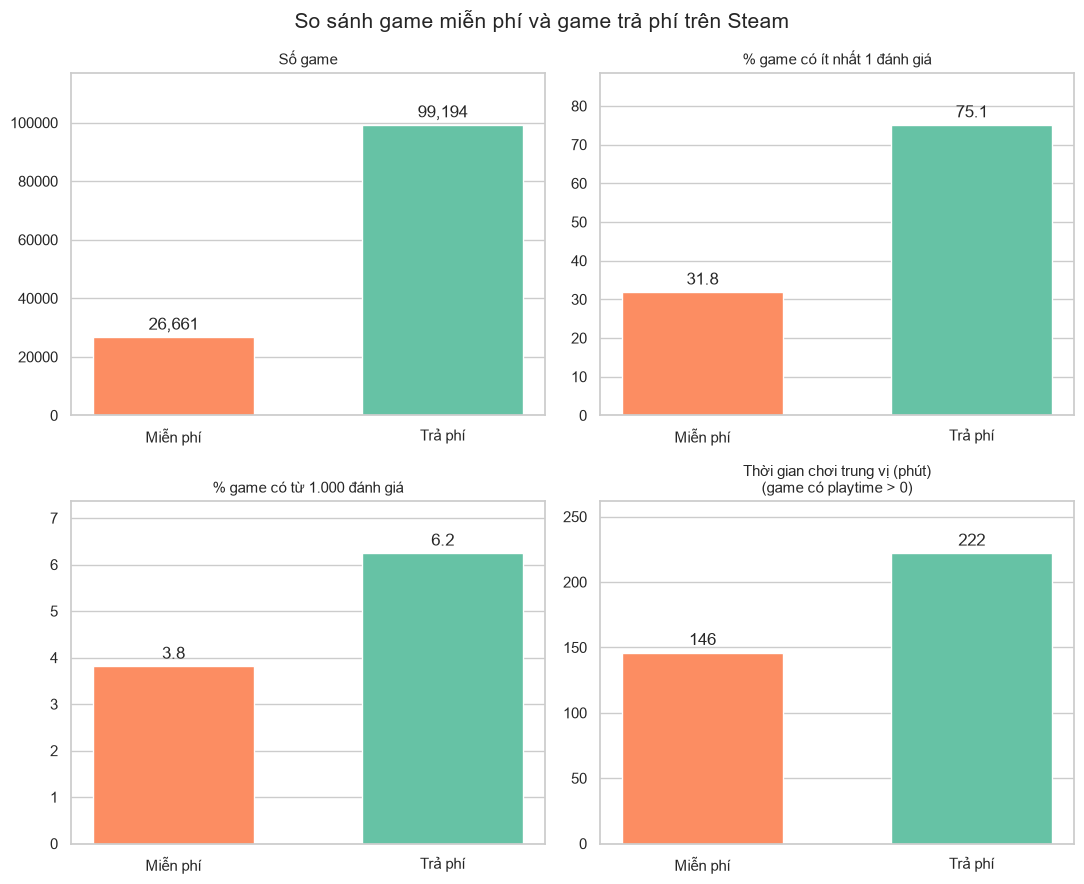

In [24]:
data = df.dropna(subset=["Price"]).copy()
data["Nhóm"] = np.where(data["Price"] == 0, "Miễn phí", "Trả phí")
data["Reviews"] = data["Positive"] + data["Negative"]

order = ["Miễn phí", "Trả phí"]
g = data.groupby("Nhóm")

metrics = [   # (tiêu đề, số liệu theo nhóm, định dạng số)
    ("Số game", g.size(), "{:,.0f}"),
    ("% game có ít nhất 1 đánh giá", g["Reviews"].apply(lambda s: (s > 0).mean() * 100), "{:.1f}"),
    ("% game có từ 1.000 đánh giá", g["Reviews"].apply(lambda s: (s >= 1000).mean() * 100), "{:.1f}"),
    ("Thời gian chơi trung vị (phút)\n(game có playtime > 0)",
     data[data["Average playtime forever"] > 0].groupby("Nhóm")["Average playtime forever"].median(), "{:,.0f}"),
]

colors = [sns.color_palette()[1], sns.color_palette()[0]]   # cam = miễn phí, xanh = trả phí
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (title, values, fmt) in zip(axes.ravel(), metrics):
    values = values.loc[order]
    ax.bar(order, values.values, color=colors, edgecolor="white", width=0.6)
    ax.bar_label(ax.containers[0], labels=[fmt.format(v) for v in values.values], padding=3)
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("So sánh game miễn phí và game trả phí trên Steam", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét

1. Số lượng: game trả phí có 99.194 game (78,8%), game miễn phí có 26.661 game (21,2%). Game trả phí nhiều gấp khoảng 3,7 lần.

2. Game miễn phí thường chưa có ai đánh giá. Chỉ 31,8% game miễn phí có ít nhất 1 đánh giá, trong khi game trả phí là 75,1%.

3. Game trả phí có tỷ lệ game nổi tiếng cao hơn: 6,2% game trả phí có từ 1.000 đánh giá, so với 3,8% ở game miễn phí. Tỷ lệ này tính trên tất cả game, nên bị kéo xuống ở game miễn phí vì 68,2% game miễn phí không có đánh giá nào.

6. Game trả phí chơi lâu hơn. Thời gian chơi trung vị là 222 phút so với 146 phút 

Kết luận: game miễn phí vừa ít hơn, vừa có nhiều game chưa có người dùng. Game trả phí có tỷ lệ game nổi tiếng cao hơn, được chơi lâu hơn và đánh giá tích cực cao hơn một chút, nhưng game miễn phí đã có người dùng thì lại nhận được nhiều đánh giá hơn.

### 2.3.6. So sánh giá giữa các thể loại game

                       so_game  pct_free  gia_tv
Genre                                           
Casual                   51677     14.72    2.99
Indie                    82884     14.41    2.99
Racing                    4169     13.53    3.49
Action                   47344     15.55    3.74
Adventure                46293     13.76    3.99
Strategy                 23058     15.11    3.99
Sports                    4971     13.82    3.99
Simulation               24912     13.18    3.99
Massively Multiplayer     2596     55.62    4.99
RPG                      21577     15.65    4.99
Utilities                 1091     29.15    4.99
Design & Illustration      584     24.66    7.99


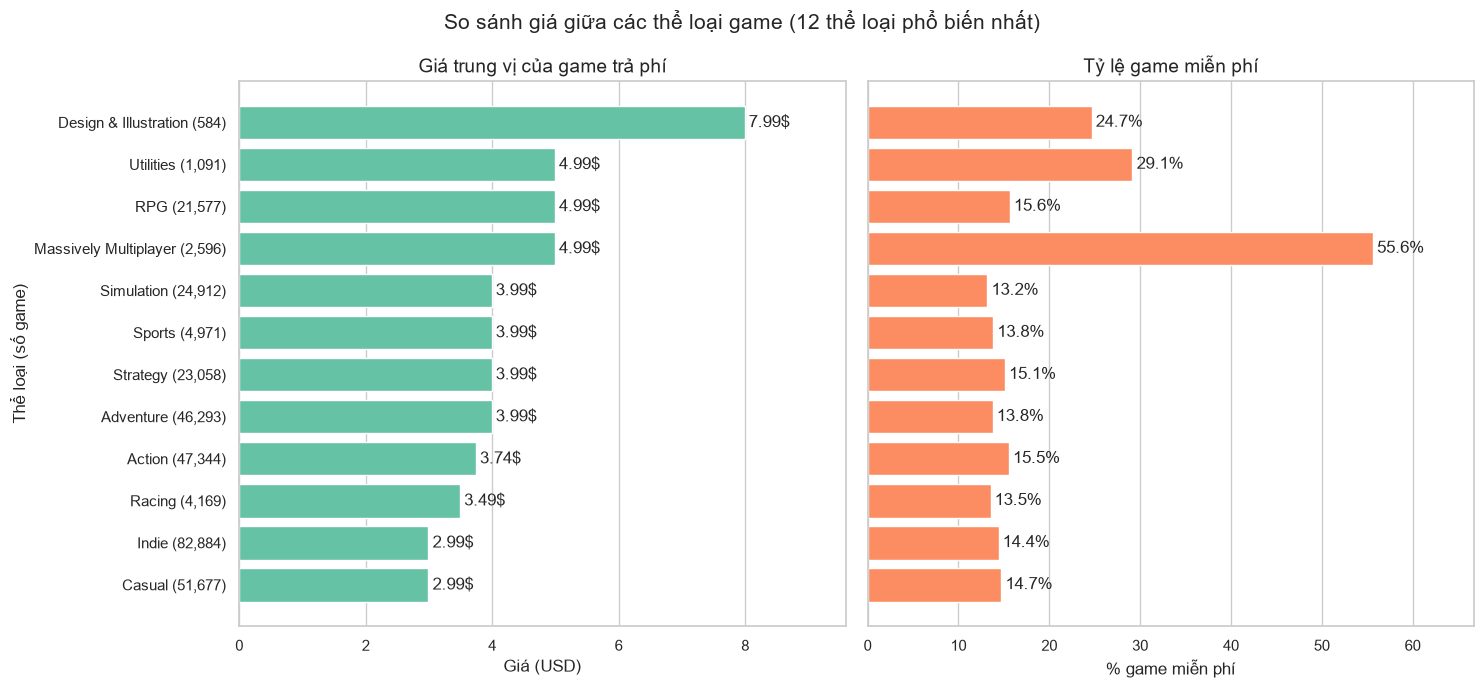

In [26]:
d = df.dropna(subset=["Genres", "Price"]).copy()
d["Genre"] = d["Genres"].str.split(",")
d = d.explode("Genre")                     # 1 game nhiều thể loại -> mỗi thể loại 1 dòng
d["Genre"] = d["Genre"].str.strip()

# bỏ 2 nhãn không phải thể loại nội dung: Free To Play (trùng với giá) và Early Access (trạng thái phát hành)
d = d[~d["Genre"].isin(["Free To Play", "Early Access"])]

top = d["Genre"].value_counts().head(12).index
d = d[d["Genre"].isin(top)]

tong_hop = d.groupby("Genre").agg(
    so_game=("Price", "size"),
    pct_free=("Price", lambda s: (s == 0).mean() * 100),
    gia_tv=("Price", lambda s: s[s > 0].median()),
).sort_values("gia_tv")
print(tong_hop.round(2))

labels = [f"{g} ({n:,})" for g, n in zip(tong_hop.index, tong_hop["so_game"])]
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

axes[0].barh(labels, tong_hop["gia_tv"], color=sns.color_palette()[0], edgecolor="white")
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.2f}$" for v in tong_hop["gia_tv"]], padding=3)
axes[0].set_xlim(0, tong_hop["gia_tv"].max() * 1.2)
axes[0].set(title="Giá trung vị của game trả phí", xlabel="Giá (USD)", ylabel="Thể loại (số game)")

axes[1].barh(labels, tong_hop["pct_free"], color=sns.color_palette()[1], edgecolor="white")
axes[1].bar_label(axes[1].containers[0], labels=[f"{v:.1f}%" for v in tong_hop["pct_free"]], padding=3)
axes[1].set_xlim(0, tong_hop["pct_free"].max() * 1.2)
axes[1].set(title="Tỷ lệ game miễn phí", xlabel="% game miễn phí")

for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("So sánh giá giữa các thể loại game (12 thể loại phổ biến nhất)", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét

1. Giá trung vị giữa các thể loại chênh nhau không nhiều.

-Hầu hết thể loại nằm trong khoảng 2,99–4,99 USD.

-Casual và Indie rẻ nhất (2,99 USD). Hai thể loại này cũng có nhiều game nhất (51.677 và 82.884 game), nên phần lớn thị trường là game giá rẻ.

-RPG, Utilities và Massively Multiplayer cùng ở mức 4,99 USD, đắt hơn nhóm rẻ nhất khoảng 1,7 lần.

### 2.3.7. So sánh các nền tảng hỗ trợ

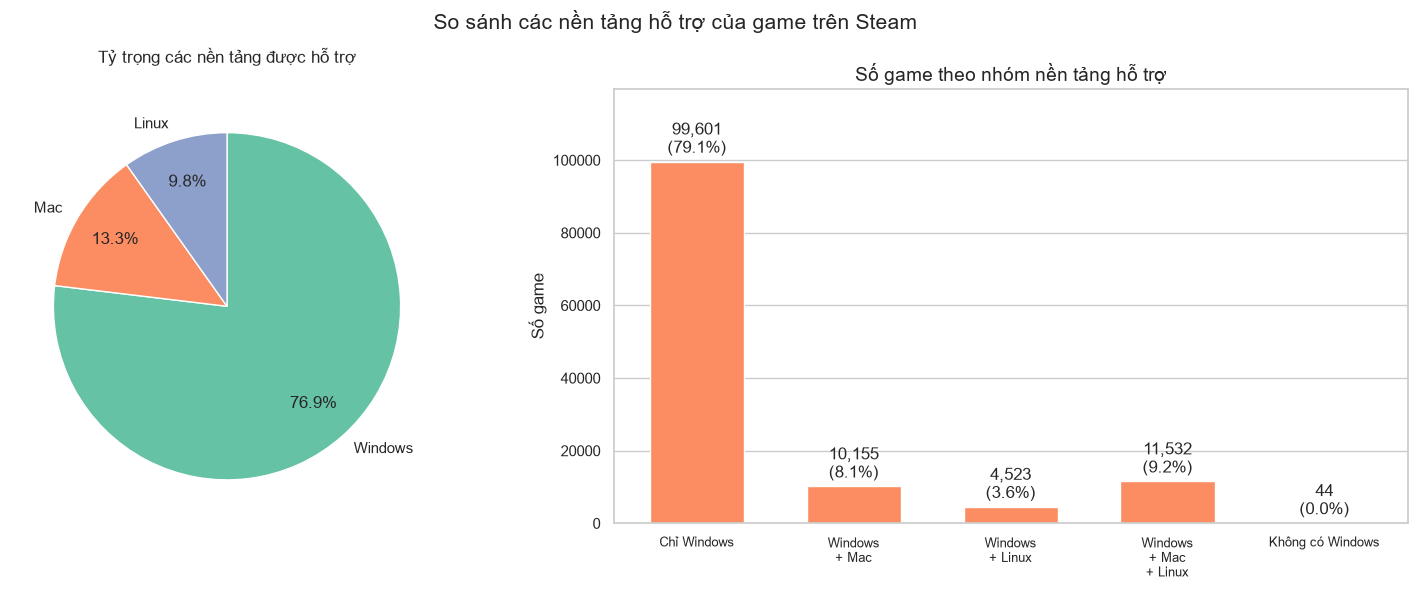

In [5]:
data = df.copy()

# 1) số game hỗ trợ từng nền tảng (dùng cho biểu đồ tròn)
so_nen_tang = data[["Windows", "Mac", "Linux"]].sum()

# 2) nhóm nền tảng hỗ trợ
data["Nhóm nền tảng"] = np.select(
    [~data["Windows"], data["Mac"] & data["Linux"], data["Mac"], data["Linux"]],
    ["Không có Windows", "Windows + Mac + Linux", "Windows + Mac", "Windows + Linux"],
    default="Chỉ Windows",
)
thu_tu = ["Chỉ Windows", "Windows + Mac", "Windows + Linux", "Windows + Mac + Linux", "Không có Windows"]
so_game = data["Nhóm nền tảng"].value_counts().reindex(thu_tu)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.4]})
mau = sns.color_palette()

ax = axes[0]
ax.pie(so_nen_tang.values,
       labels=list(so_nen_tang.index),
       autopct="%1.1f%%", startangle=90, counterclock=False, colors=mau[:3],
       wedgeprops={"edgecolor": "white"}, pctdistance=0.75)
ax.set_title("Tỷ trọng các nền tảng được hỗ trợ\n", fontsize=12)
ax.grid(False)

ax = axes[1]
ax.bar(range(len(so_game)), so_game.values, color=mau[1], edgecolor="white", width=0.6)
ax.bar_label(ax.containers[0],
             labels=[f"{n:,}\n({n / so_game.sum() * 100:.1f}%)" for n in so_game.values], padding=3)
ax.set_ylim(0, so_game.max() * 1.2)
ax.set_xticks(range(len(thu_tu))); ax.set_xticklabels([t.replace(" + ", "\n+ ") for t in thu_tu], fontsize=9)
ax.grid(axis="x", visible=False)
ax.set(title="Số game theo nhóm nền tảng hỗ trợ", ylabel="Số game")

fig.suptitle("So sánh các nền tảng hỗ trợ của game trên Steam", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét:

-Windows chiếm 76,9%, Mac 13,3% và Linux 9,8%. Windows chiếm áp đảo, Mac và Linux cộng lại chưa tới một phần tư. Ta có thể thấy rằng là xu hướng hiện nay các nhà phát triển game vẫn ưu tiên hỗ trợ nền tảng Window là chính. Nền tảng Mac, Linux vẫn có nhưng chưa được phổ biến như Window

### 2.3.8. Số lượng game theo năm phát hành 

Số game không đọc được ngày phát hành: 0


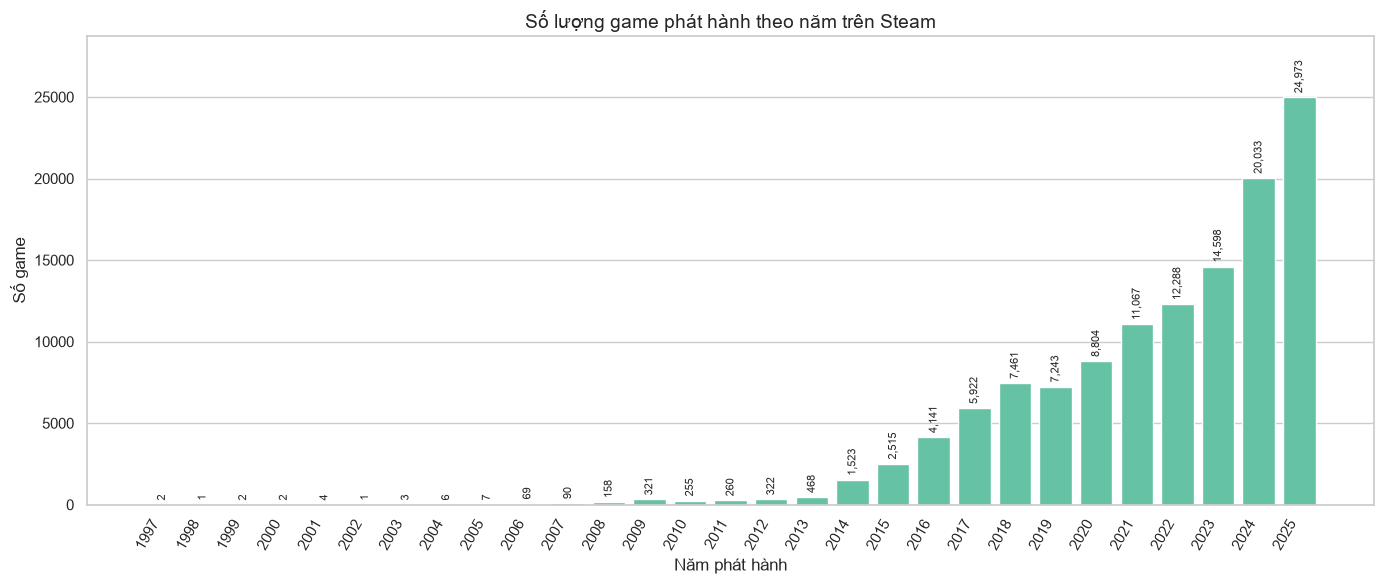

In [7]:
ngay = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
print("Số game không đọc được ngày phát hành:", ngay.isna().sum())

nam = ngay.dt.year.dropna().astype(int)
so_game = nam.value_counts().sort_index()
so_game = so_game[so_game.index <= 2025]          # bỏ năm 2026 (dữ liệu chưa đủ năm)

plt.figure(figsize=(14, 6))
ax = plt.gca()
ax.bar(so_game.index, so_game.values, color=sns.color_palette()[0], edgecolor="white")
ax.bar_label(ax.containers[0], labels=[f"{v:,}" for v in so_game.values], rotation=90, fontsize=8, padding=3)
ax.set_xticks(so_game.index)
ax.set_xticklabels(so_game.index, rotation=60, ha="right")
ax.set_ylim(0, so_game.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set(title="Số lượng game phát hành theo năm trên Steam",
       xlabel="Năm phát hành", ylabel="Số game")
plt.tight_layout()
plt.show()

Nhận xét:

-Số game phát hành mỗi năm tăng mạnh và gần như liên tục. Trước 2006, mỗi năm chỉ có 1–7 game. Từ 2014 số game bắt đầu tăng nhanh (1.523 game), đến 2025 đạt 24.973 game, gấp khoảng 3,3 lần năm 2018 và 2,8 lần năm 2020. Chỉ có một năm giảm nhẹ là 2019 (−2,9%), sau đó tăng trở lại. Xu hướng cho thấy thị trường game trên Steam mở rộng rất nhanh, nhất là trong những năm gần đây.

-Năm 2023 có 14.598 game, năm 2024 có 20.033 game, tức tăng thêm 5.435 game, tương ứng +37,2%. Đây là mức tăng phần trăm cao nhất kể từ 2017.

-Năm 2025 có 24.973 game, tăng thêm 4.940 game so với 2024, tương ứng +24,7%. Tốc độ tăng chậm lại so với năm trước (37,2% xuống 24,7%) nhưng số game tăng thêm vẫn rất lớn.


In [8]:
%pip install seaborn matplotlib


Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\ADMIN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
""" #34 – Phân tích tương quan (Correlation Analysis)"""

In [9]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Thư mục dự án:", PROJECT_ROOT)
print("Tìm thấy src:", (PROJECT_ROOT / "src").exists())

Thư mục dự án: c:\Users\ADMIN\OneDrive\Documents\Gamesteam\Games_Data_Science
Tìm thấy src: True


# Đọc dữ liệu và kiểm tra các cột số

In [3]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "games_cleaned.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Kích thước dữ liệu:", df.shape)
print("\nCác cột số:")
print(df.select_dtypes(include="number").columns.tolist())

Kích thước dữ liệu: (125855, 39)

Các cột số:
['AppID', 'Peak CCU', 'Required age', 'Price', 'DiscountDLC count', 'About the game', 'Metacritic url', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers']


""" Chọn các biến để phân tích
Ban đầu, hãy thử với các biến sau:
Biến	Ý nghĩa
Price	Giá game
Positive	Số đánh giá tích cực
Negative	Số đánh giá tiêu cực
Peak CCU	Số người chơi đồng thời đạt đỉnh
Recommendations	Số lượt đề xuất
Metacritic score	Điểm đánh giá Metacritic

Tên và ý nghĩa các cột dựa trên bộ dữ liệu Steam Games bạn đang sử dụng. 
Cần xác nhận chúng có tồn tại và được đọc đúng kiểu dữ liệu trước khi phân tích."""

# Tính ma trận tương quan

In [2]:
columns = [
    "Price",
    "Positive",
    "Negative",
    "Peak CCU",
    "Recommendations",
    "Metacritic score"
]

available_columns = [
    col for col in columns
    if col in df.columns
]

numeric_df = df[available_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

correlation_matrix = numeric_df.corr(method="pearson")

display(correlation_matrix.round(2))

,Price,Positive,Negative,Peak CCU,Recommendations,Metacritic score
Price,1.00,-0.00,0.01,0.00,-0.00,0.06
Positive,-0.00,1.00,-0.00,-0.00,0.00,0.01
Negative,0.01,-0.00,1.00,0.85,0.01,0.02
Peak CCU,0.00,-0.00,0.85,1.00,0.00,0.01
Recommendations,-0.00,0.00,0.01,0.00,1.00,0.02
Metacritic score,0.06,0.01,0.02,0.01,0.02,1.00


# Vẽ heatmap

In [13]:
#Kiểm tra các hàm có trong plots.py(chạy vì bị lỗi không gọi được hàm để vẽ heatmap)
import importlib
import src.plots as plots

importlib.reload(plots)

print([name for name in dir(plots) if name.startswith("plot_")])

['plot_correlation_heatmap', 'plot_histogram']


In [5]:
from pathlib import Path

print("Thư mục hiện tại:", Path.cwd())
print("Thư mục src tồn tại:", (Path.cwd().parent / "src").exists())

Thư mục hiện tại: c:\Users\ADMIN\OneDrive\Documents\Gamesteam\Games_Data_Science\notebooks
Thư mục src tồn tại: True


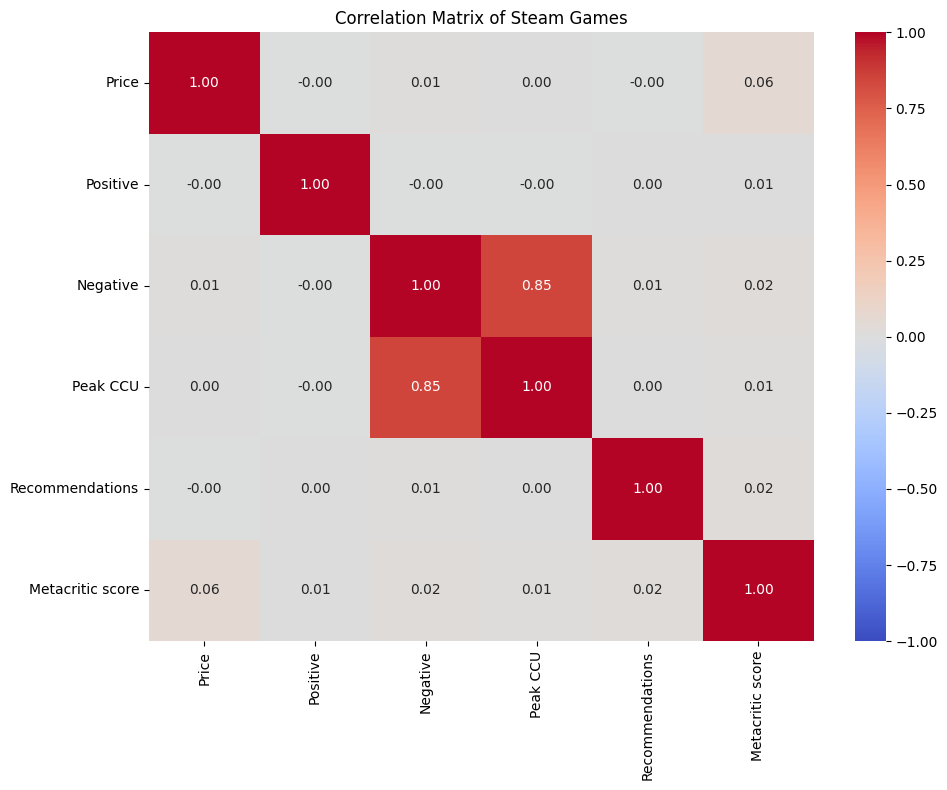

In [15]:
plots.plot_correlation_heatmap(correlation_matrix)

# xong 34

In [ ]:
-------------------------------

# #35 – Trực quan hóa dữ liệu rõ ràng

In [16]:
import importlib
import src.plots as plots

importlib.reload(plots)

<module 'src.plots' from 'c:\\Users\\ADMIN\\OneDrive\\Documents\\Gamesteam\\Games_Data_Science\\src\\plots.py'>

## Vẽ biểu đồ giá game bằng hàm plot_histogram

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Distribution of Game Prices'}, xlabel='Price', ylabel='Count'>)

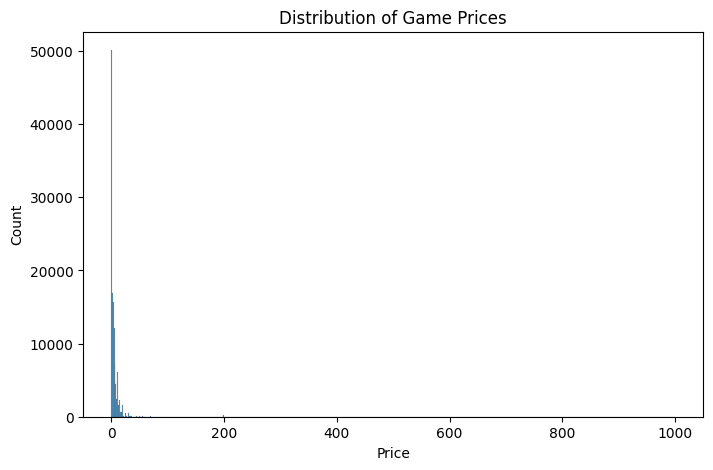

In [17]:
plots.plot_histogram(df["Price"], title="Distribution of Game Prices")

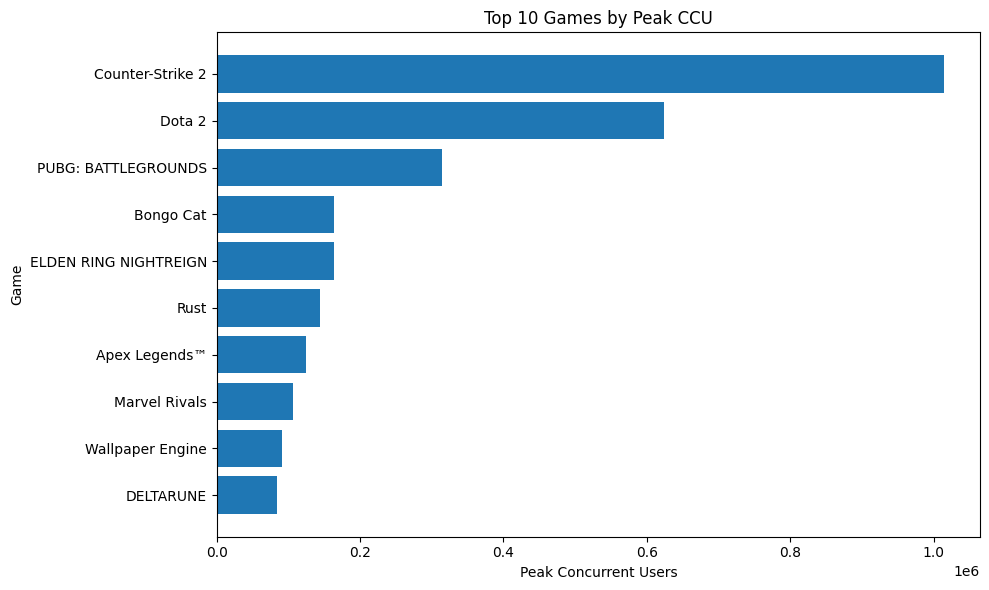

In [18]:
plots.plot_top_peak_ccu(df, top_n=10)

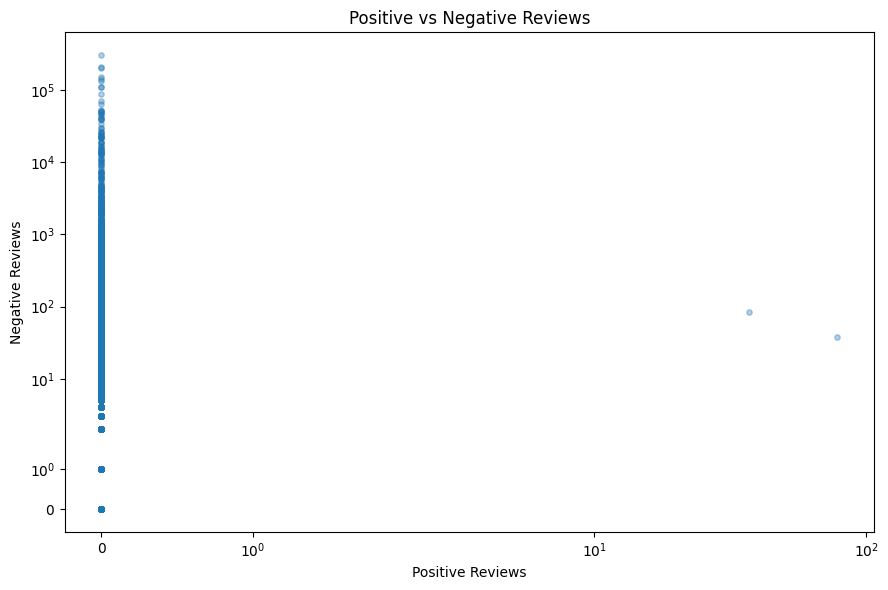

In [19]:
plots.plot_positive_negative_reviews(df)

# xong 35

In [ ]:
-------------------------------

# 36 – Phát hiện giả thuyết, xu hướng và điểm bất thường (Patterns, Hypotheses & Anomalies)

# Kiểm tra giả thuyết về mức độ tập trung người chơi

In [20]:
#Tính tỷ trọng Peak CCU của Top 10 game

import pandas as pd

# Chuyen Peak CCU sang dang so
df["Peak CCU"] = pd.to_numeric(
    df["Peak CCU"], errors="coerce"
)

# Loai bo gia tri thieu va gia tri am
ccu = df.loc[df["Peak CCU"] >= 0, "Peak CCU"].dropna()

# Tinh tong Peak CCU cua tat ca game
total_ccu = ccu.sum()

# Tinh tong Peak CCU cua 10 game cao nhat
top10_ccu = ccu.nlargest(10).sum()

# In ket qua
print(f"So game hop le: {len(ccu):,}")
print(f"Tong Peak CCU: {total_ccu:,.0f}")
print(f"Top 10 Peak CCU: {top10_ccu:,.0f}")

if total_ccu > 0:
    ratio = top10_ccu / total_ccu
    print(f"Ty trong Top 10: {ratio:.2%}")


So game hop le: 125,855
Tong Peak CCU: 6,693,875
Top 10 Peak CCU: 2,830,189
Ty trong Top 10: 42.28%


In [ ]:
"""- Chỉ 10 game trong tổng số 125.855 game đã chiếm khoảng 42,28% tổng các giá trị Peak CCU.
- Điều này cho thấy các giá trị người chơi đồng thời cao nhất tập trung đáng kể vào một nhóm nhỏ game.
- Đây là bằng chứng ủng hộ giả thuyết về sự tập trung của Peak CCU.
Lưu ý: Đây là tỷ trọng tổng các giá trị Peak CCU của từng game, không phải tỷ trọng người chơi duy nhất trên toàn Steam. Mỗi game có thể ghi nhận đỉnh người chơi vào thời điểm khác nhau."""

# Kiểm tra xu hướng giá game

In [4]:
#Thống kê phân phối giá
"""Nếu giá trung bình lớn hơn trung vị đáng kể, một số giá cao có thể đang kéo trung bình lên.



Nếu tỷ lệ giá bằng 0 cao, game miễn phí là một nhóm đáng chú ý trong dữ liệu.



Giá cao nhất chưa chắc là dữ liệu sai; cần kiểm tra từng trường hợp trước khi kết luận."""

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

price = df.loc[df["Price"] >= 0, "Price"].dropna()

print("So game co gia hop le:", len(price))
print("Gia trung binh:", round(price.mean(), 2))
print("Gia trung vi:", round(price.median(), 2))
print("Gia 75%:", round(price.quantile(0.75), 2))
print("Gia cao nhat:", round(price.max(), 2))

print("\nTy le game mien phi:")
print(f"{(price == 0).mean():.2%}")


So game co gia hop le: 125855
Gia trung binh: 4.81
Gia trung vi: 2.39
Gia 75%: 5.54
Gia cao nhat: 999.98

Ty le game mien phi:
21.18%


In [ ]:
"""Nhận xét:
- Giá trung bình 4,81 cao hơn đáng kể so với trung vị 2,39. Điều này phù hợp với dấu hiệu phân phối lệch phải: một số giá cao kéo mức trung bình lên.
- 75% game có giá không vượt quá 5,54, trong khi giá cao nhất là 999,98. Đây là một giá trị cực trị đáng kiểm tra.
- 21,18% game có giá bằng 0, cho thấy nhóm game miễn phí chiếm tỷ lệ đáng kể.
Giả thuyết: Phần lớn game có giá tương đối thấp, trong khi một nhóm nhỏ có giá cao hơn nhiều.
 Tuy nhiên, giá 999,98 chưa thể được xem là lỗi nếu chưa kiểm tra thông tin game tương ứng."""

# Kiểm tra những game có ít đánh giá

In [5]:
#Thống kê số lượt đánh giá
"""Biểu đồ Positive vs Negative Reviews cho thấy nhiều điểm nằm sát phía trái. 
Điều này có thể do nhiều game có số lượt đánh giá thấp.
 Ta cần kiểm tra bằng số liệu thay vì đoán."""


df["Positive"] = pd.to_numeric(df["Positive"], errors="coerce")
df["Negative"] = pd.to_numeric(df["Negative"], errors="coerce")

reviews = df[["Positive", "Negative"]].dropna()

reviews["Total Reviews"] = (
    reviews["Positive"] + reviews["Negative"]
)

print("Số game có dữ liệu đánh giá:", len(reviews))
print("Số game chưa có đánh giá:",
      (reviews["Total Reviews"] == 0).sum())
print("Số game có dưới 10 lượt đánh giá:",
      (reviews["Total Reviews"] < 10).sum())
print("Số game có trên 1.000 lượt đánh giá:",
      (reviews["Total Reviews"] > 1000).sum())


Số game có dữ liệu đánh giá: 125855
Số game chưa có đánh giá: 45509
Số game có dưới 10 lượt đánh giá: 74112
Số game có trên 1.000 lượt đánh giá: 6408


In [ ]:
"""Nhận xét:
- Khoảng 36,17% game chưa có đánh giá nào.
- Khoảng 58,89% game có dưới 10 lượt đánh giá.
- Chỉ khoảng 5,09% game có trên 1.000 lượt đánh giá.
Điều này cho thấy số lượt đánh giá phân bố không đồng đều giữa các game.
 Nhiều game có rất ít đánh giá, trong khi một nhóm nhỏ nhận được nhiều đánh giá hơn đáng kể.

Đây cũng là lý do biểu đồ Positive vs Negative Reviews tập trung dày ở gần gốc tọa độ. 
Tuy nhiên, cần nhớ rằng số lượt đánh giá ít không đồng nghĩa với dữ liệu sai."""

### Nhiệm vụ #36 – Phát hiện giả thuyết, xu hướng và điểm bất thường

**1. Mức độ tập trung Peak CCU**

Top 10 game có tổng Peak CCU là 2.830.189, chiếm 42,28% tổng Peak CCU của bộ dữ liệu. Kết quả cho thấy các giá trị Peak CCU tập trung đáng kể vào nhóm game dẫn đầu. Tuy nhiên, đây không phải tỷ trọng người chơi duy nhất trên toàn Steam.

**2. Xu hướng giá game**

Giá trung bình là 4,81, cao hơn trung vị 2,39. Phân vị 75% là 5,54, trong khi giá cao nhất đạt 999,98. Kết quả phù hợp với dấu hiệu phân phối giá lệch phải. Khoảng 21,18% game có giá bằng 0. Giá cao nhất cần được kiểm tra thêm trước khi kết luận là dữ liệu sai.

**3. Mức độ phổ biến của đánh giá**

Trong 125.855 game, có 45.509 game chưa có đánh giá và 74.112 game có dưới 10 lượt đánh giá. Chỉ 6.408 game có trên 1.000 lượt đánh giá. Điều này cho thấy số lượt đánh giá phân bố không đồng đều giữa các game.

**4. Điểm cần kiểm tra thêm**

- Xác minh game có giá 999,98.
- Kiểm tra các game có giá trị đánh giá bằng 0 để phân biệt game chưa có đánh giá với trường hợp dữ liệu thiếu hoặc sai.
- Tiếp tục xác minh các giá trị cực trị trước khi quyết định có cần làm sạch hay không.

**Kết luận:** Phân tích đã phát hiện các xu hướng về mức độ tập trung Peak CCU, phân phối giá và số lượt đánh giá. Những kết quả này hỗ trợ việc hình thành giả thuyết và xác định các trường hợp cần kiểm tra thêm, nhưng không tự chứng minh quan hệ nhân quả.
